# 03 — Forecasting

Feature construction, model training, walk-forward evaluation and metrics (Req 7.3), following `docs/forecasting_protocol.md` v1.1. **Runtime: tens of minutes** (test refits at every step, as Req 5.6 requires).

*Data: CEDA Agri Market Data, Centre for Economic Data and Analysis (CEDA), Ashoka University; original source DMI, Ministry of Agriculture and Farmers Welfare (Agmarknet).*

In [1]:
import os, sys
from pathlib import Path
# Run from the repository root so `src` and configured relative paths resolve
root = Path.cwd()
while not (root / "configs" / "config.json").exists() and root != root.parent:
    root = root.parent
os.chdir(root)
sys.path.insert(0, str(root))
import json
import pandas as pd
from IPython.display import Image, Markdown, display
from src.config import load_config, resolve_path
cfg = load_config()
tables = resolve_path(cfg["paths"]["tables_dir"])
figs = resolve_path(cfg["paths"]["figures_dir"])
print("Repository root:", root)

Repository root: D:\MY works\CropCast


## Feature-availability audit (Req 4.8)

In [2]:
from src.features.build import feature_audit_table
feature_audit_table()

,feature,derivation,latest_index_used,uses_future_data,leakage_check
0,price_lag_1,modal price at market-day index t-0,t-0,No,tests/test_features.py: perturbing values afte...
1,price_lag_2,modal price at market-day index t-1,t-1,No,tests/test_features.py: perturbing values afte...
2,price_lag_3,modal price at market-day index t-2,t-2,No,tests/test_features.py: perturbing values afte...
3,price_lag_5,modal price at market-day index t-4,t-4,No,tests/test_features.py: perturbing values afte...
4,price_lag_7,modal price at market-day index t-6,t-6,No,tests/test_features.py: perturbing values afte...
5,roll_mean_7,mean of modal price over indices t-6..t,t,No,tests/test_features.py: perturbing values afte...
6,roll_std_7,sample SD of modal price over indices t-6..t,t,No,tests/test_features.py: perturbing values afte...
7,roll_mean_14,mean of modal price over indices t-13..t,t,No,tests/test_features.py: perturbing values afte...
8,roll_std_14,sample SD of modal price over indices t-13..t,t,No,tests/test_features.py: perturbing values afte...
9,arrival_lag_1,arrivals at index t-0,t-0,No,tests/test_features.py: perturbing values afte...


## Run validation tuning and the walk-forward test

In [3]:
from src.forecasting.run import Runner
Runner(cfg).run()

warning (first occurrence; all occurrences are counted in the run manifest): EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters. [D:\MY works\CropCast\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679]


warning (first occurrence; all occurrences are counted in the run manifest): EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters. [D:\MY works\CropCast\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679]


warning (first occurrence; all occurrences are counted in the run manifest): ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals [D:\MY works\CropCast\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737]


           series_id             model        mae       rmse  mape_pct     mase   dm_stat         p_bh                        verdict
   onion_maharashtra               ets  60.035407  85.584602  4.008330 0.836206 -1.520421 1.738065e-01      no significant difference
   onion_maharashtra            sarima  60.575051  85.606248  4.023256 0.843722 -1.411932 1.903045e-01      no significant difference
   onion_maharashtra     random_forest  61.628873  87.372757  4.148513 0.858400 -0.763310 4.861483e-01      no significant difference
   onion_maharashtra             naive  62.747368  88.598550  4.313644 0.873979       NaN          NaN                       baseline
   onion_maharashtra linear_regression  63.714916  90.163723  4.195045 0.887456  0.573943 5.662622e-01      no significant difference
   onion_maharashtra     decision_tree  65.357404  92.505935  4.399335 0.910333  1.515175 1.738065e-01      no significant difference
   onion_maharashtra    seasonal_naive 142.459208 204.918575  

[WindowsPath('D:/MY works/CropCast/reports/forecasts/test_onion_maharashtra.csv'),
 WindowsPath('D:/MY works/CropCast/reports/forecasts/test_potato_uttar_pradesh.csv'),
 WindowsPath('D:/MY works/CropCast/reports/tables/forecast_validation_results.csv'),
 WindowsPath('D:/MY works/CropCast/reports/tables/forecast_sarima_aic.csv'),
 WindowsPath('D:/MY works/CropCast/reports/tables/forecast_test_selection.csv'),
 WindowsPath('D:/MY works/CropCast/reports/tables/forecast_test_metrics.csv'),
 WindowsPath('D:/MY works/CropCast/reports/tables/forecast_test_breakdown.csv'),
 WindowsPath('D:/MY works/CropCast/figures/fig13_residuals_onion_maharashtra.png'),
 WindowsPath('D:/MY works/CropCast/figures/fig13_residuals_potato_uttar_pradesh.png'),
 WindowsPath('D:/MY works/CropCast/figures/fig14_test_forecasts.png')]

In [4]:
m = pd.read_csv(tables / 'forecast_test_metrics.csv')
m[['series_id','model','mae','rmse','mape_pct','mase','mae_vs_naive_pct','dm_stat','p_bh','verdict']].round(4)

,series_id,model,mae,rmse,mape_pct,mase,mae_vs_naive_pct,dm_stat,p_bh,verdict
0,onion_maharashtra,ets,60.0354,85.5846,4.0083,0.8362,-4.3220,-1.5204,0.1738,no significant difference
1,onion_maharashtra,sarima,60.5751,85.6062,4.0233,0.8437,-3.4620,-1.4119,0.1903,no significant difference
2,onion_maharashtra,random_forest,61.6289,87.3728,4.1485,0.8584,-1.7825,-0.7633,0.4861,no significant difference
3,onion_maharashtra,naive,62.7474,88.5985,4.3136,0.8740,0.0000,NaN,NaN,baseline
4,onion_maharashtra,linear_regression,63.7149,90.1637,4.1950,0.8875,1.5420,0.5739,0.5663,no significant difference
5,onion_maharashtra,decision_tree,65.3574,92.5059,4.3993,0.9103,4.1596,1.5152,0.1738,no significant difference
6,onion_maharashtra,seasonal_naive,142.4592,204.9186,9.0719,1.9842,127.0362,12.4421,0.0000,significantly worse than naive
7,potato_uttar_pradesh,random_forest,10.7674,14.3914,0.9412,0.8298,-26.3240,-7.9313,0.0000,improves on naive
8,potato_uttar_pradesh,sarima,10.9671,14.7483,0.9591,0.8452,-24.9576,-6.8699,0.0000,improves on naive
9,potato_uttar_pradesh,ets,11.1353,14.9489,0.9736,0.8582,-23.8066,-6.2294,0.0000,improves on naive


In [5]:
v = pd.read_csv(tables / 'forecast_validation_results.csv')
v.sort_values(['series_id','val_mae']).groupby('series_id').head(8)

,series_id,family,params,val_mae,val_rmse,config_hash,seconds
14,onion_maharashtra,random_forest,"{""max_depth"": 5, ""max_features"": 1.0, ""min_sam...",98.368180,163.559241,1d2e74016a524f6dd4775fb9e2d1b5330fba23be3a3b15...,62.710959
12,onion_maharashtra,random_forest,"{""max_depth"": 5, ""max_features"": 0.5, ""min_sam...",98.729693,163.922367,e419f236403a58e838ecb6a3eb9c91cc97bca2843ad26c...,60.863357
16,onion_maharashtra,random_forest,"{""max_depth"": 10, ""max_features"": 0.5, ""min_sa...",99.166129,164.495528,17cb67955d340cbbd47875ffff8a79f9921631bcdd22cf...,47.333040
20,onion_maharashtra,random_forest,"{""max_depth"": null, ""max_features"": 0.5, ""min_...",99.223578,164.340088,63d715050dd11b39cf0a7ebfcab867e7bb8e96ca698103...,50.111308
18,onion_maharashtra,random_forest,"{""max_depth"": 10, ""max_features"": 1.0, ""min_sa...",99.229236,164.680081,c5985cab00af4ea6260083c8b09da3463a17e5d2877750...,85.679069
15,onion_maharashtra,random_forest,"{""max_depth"": 5, ""max_features"": 1.0, ""min_sam...",99.312893,165.778728,e99399fb85b66105b31b80ad52d0f69ad4eb70c841542b...,59.237767
22,onion_maharashtra,random_forest,"{""max_depth"": null, ""max_features"": 1.0, ""min_...",99.369210,164.790622,c40fe8dca7ba3e2cf26349743ddf60051b2755fa04025b...,72.563878
17,onion_maharashtra,random_forest,"{""max_depth"": 10, ""max_features"": 0.5, ""min_sa...",99.427050,164.780327,264062b0e43890e3a1ded428a7aa5688d3a7dee4afed1f...,41.843244
45,potato_uttar_pradesh,random_forest,"{""max_depth"": 10, ""max_features"": 0.5, ""min_sa...",14.762616,27.049986,f4117dcdaf3386a254626f81f144c950b23732fa8daca1...,43.516883
49,potato_uttar_pradesh,random_forest,"{""max_depth"": null, ""max_features"": 0.5, ""min_...",14.896518,27.152895,903e89fa26e4778a97bc9f739307846803f0c070eddeb2...,50.301099


In [6]:
b = pd.read_csv(tables / 'forecast_test_breakdown.csv')
b[b.breakdown == 'half_year'].pivot_table(index=['series_id','level'], columns='model', values='mae').round(1)

model                         decision_tree   ets  linear_regression  naive  \
series_id            level                                                    
onion_maharashtra    2021-H2           93.6  85.9               94.5   83.9   
                     2022-H1           51.4  47.0               50.4   48.9   
                     2022-H2           57.7  53.2               53.4   60.2   
potato_uttar_pradesh 2021-H2           12.8  10.9               11.9   15.9   
                     2022-H1            9.4   8.9                9.6   11.9   
                     2022-H2           13.9  13.5               14.0   16.2   

model                         random_forest  sarima  seasonal_naive  
series_id            level                                           
onion_maharashtra    2021-H2           88.4    87.8           202.5  
                     2022-H1           48.5    46.4           114.9  
                     2022-H2           54.1    53.9           123.9  
potato_uttar_pradesh 2021-H2           10.4    10.7            52.4  
                     2022-H1            8.7     9.0            27.3  
                     2022-H2           13.1    13.2            39.1

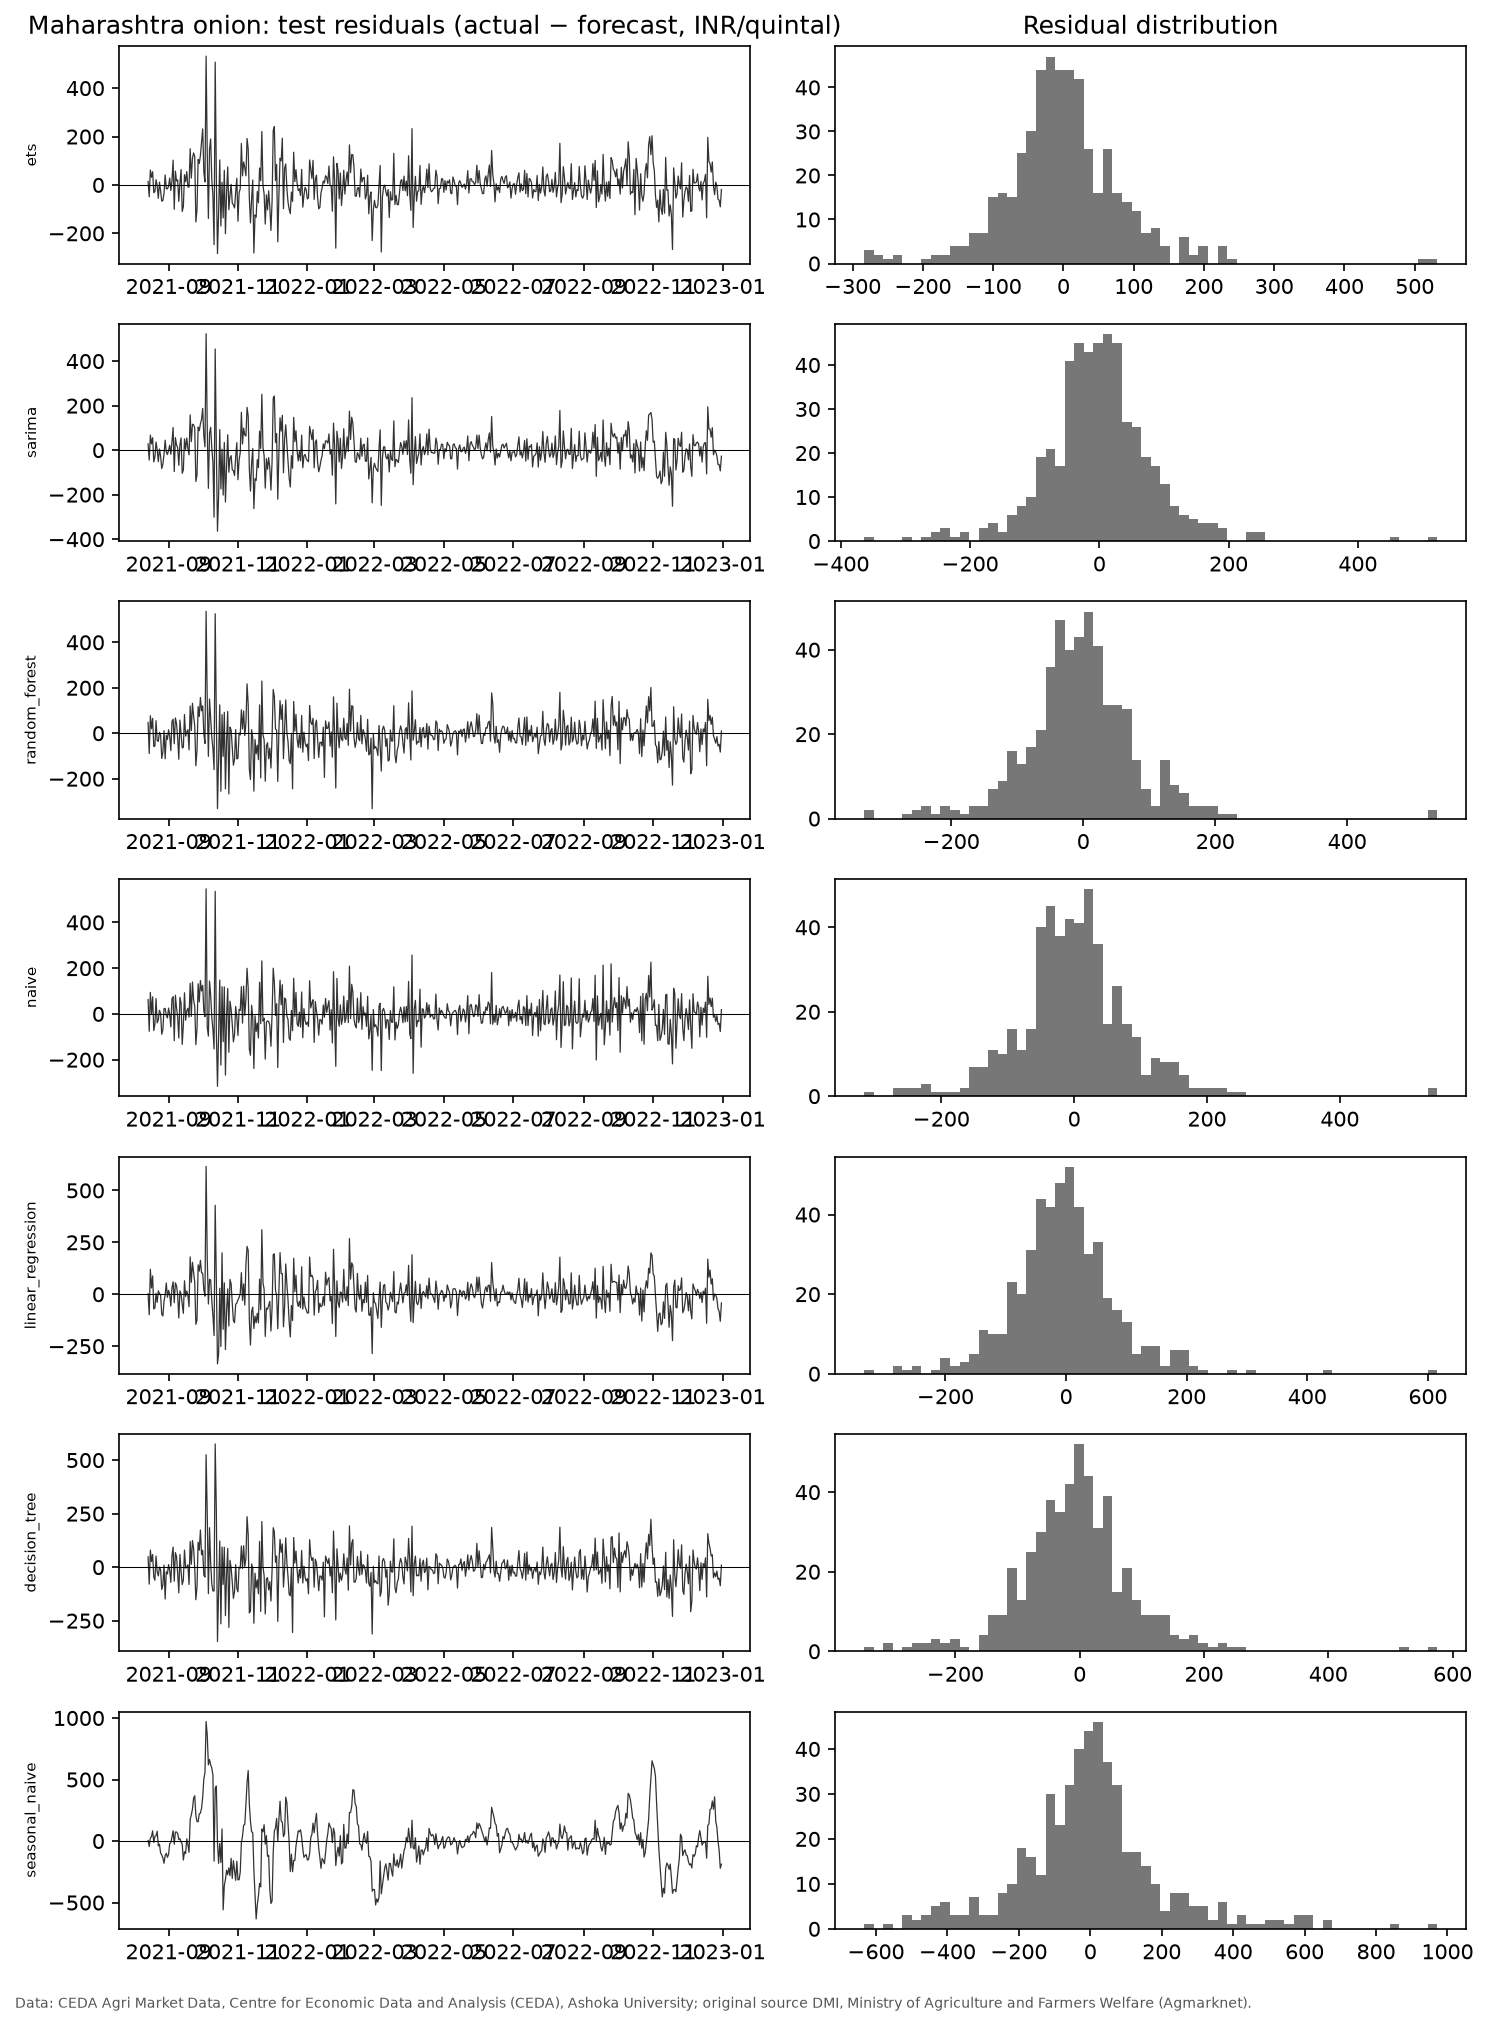

In [7]:
display(Image(filename=str(figs / 'fig13_residuals_onion_maharashtra.png')))

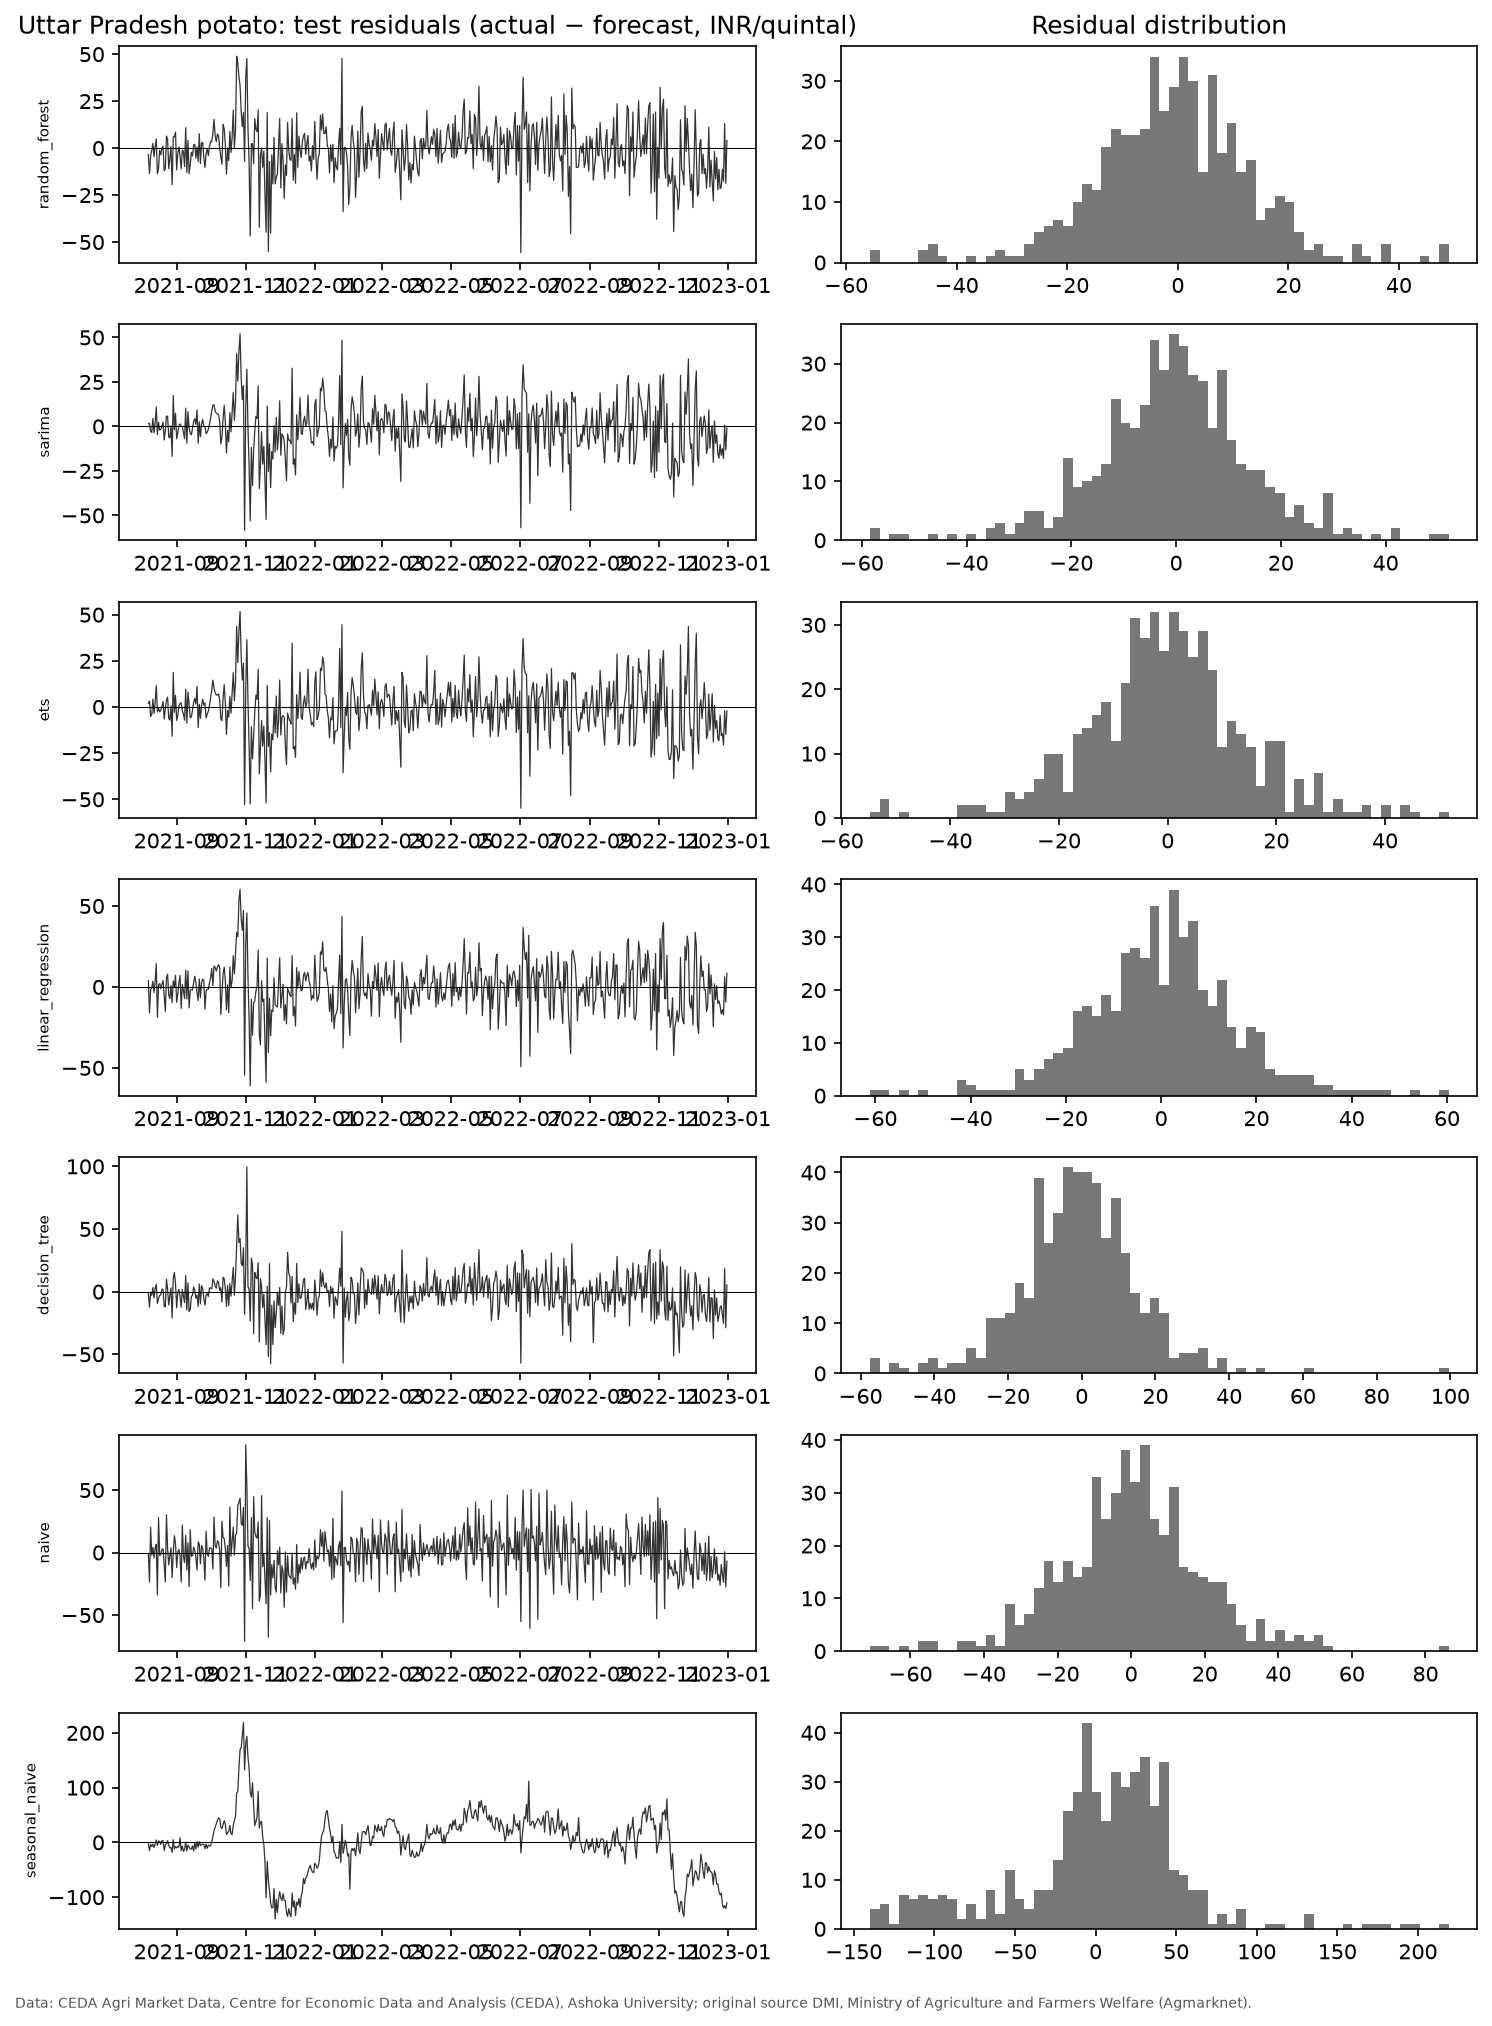

In [8]:
display(Image(filename=str(figs / 'fig13_residuals_potato_uttar_pradesh.png')))

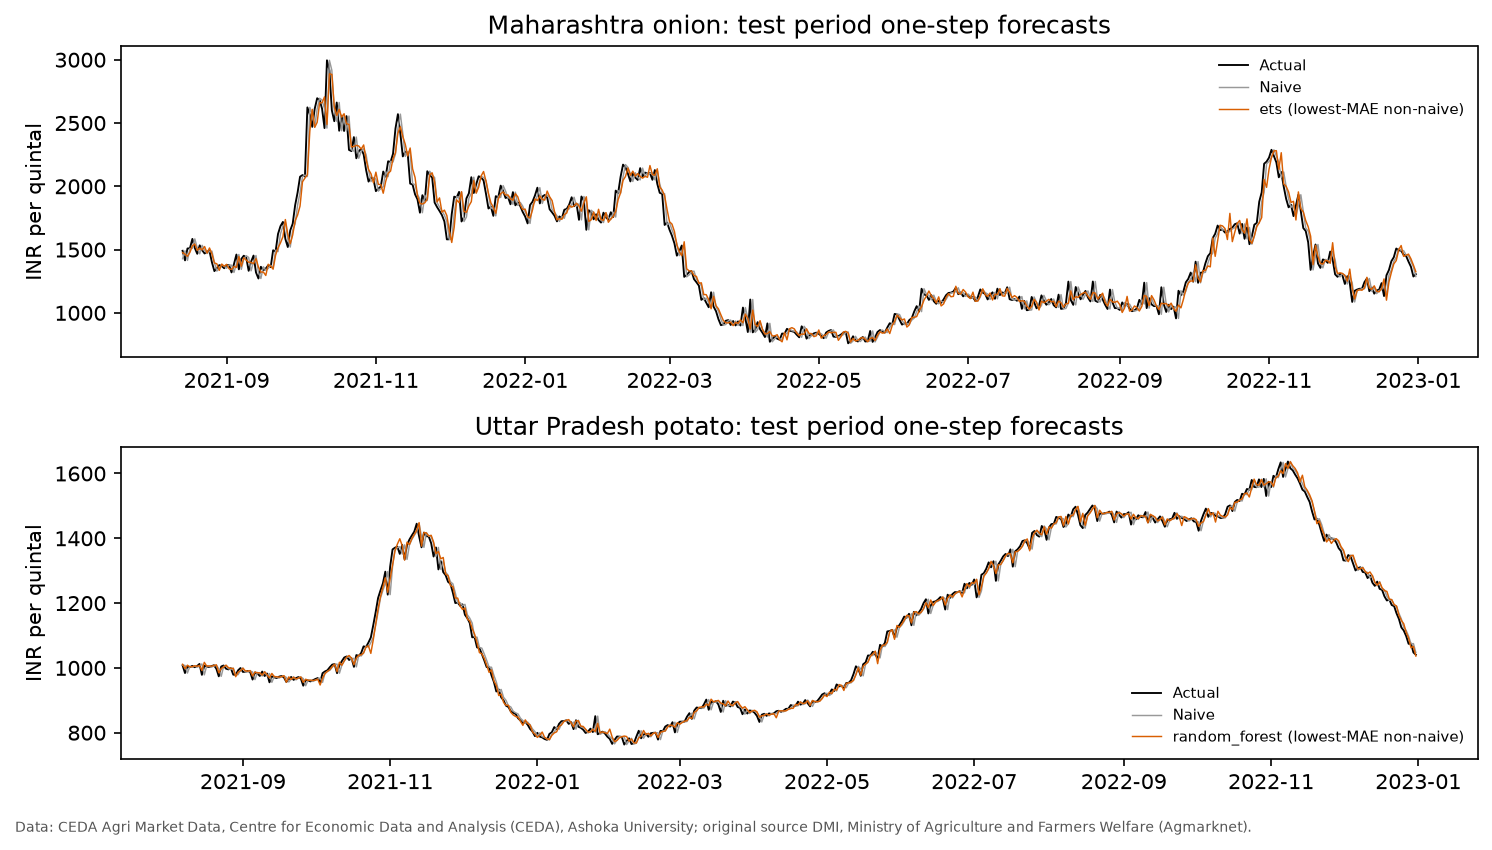

In [9]:
display(Image(filename=str(figs / 'fig14_test_forecasts.png')))